# Vertical Coherence

In [8]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
from dotenv import find_dotenv, load_dotenv
from tqdm import tqdm

from nescafe23_fluctuations import tools

load_dotenv(find_dotenv())

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## estimate observed vertical coherence

In [10]:
fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/wavefront_values.pkl"

with open(fn, "rb") as f:
    wavefront_values = pickle.load(f)

In [11]:
MC = {}
AC = {}
MC_var = {}

for k, ray_id in enumerate(wavefront_values.keys()):
    dz, MC[ray_id], MC_var[ray_id] = tools.estimate_mutual_coherence(
        wavefront_values[ray_id], 9
    )

    _, AC[ray_id], _ = tools.estimate_mutual_coherence(
        np.abs(wavefront_values[ray_id]), 9
    )

## compute path integral vertical coherence

In [15]:
latitude = 39.192499999
Omega = 7.292115e-5  # Earth Rotation Speed [rad/s]
f = 2 * Omega * np.sin(np.radians(latitude))  # [rad/s]

zeta0 = 7.3 * np.sqrt(2)
rvs = tools.compute_n23_ray_variables(f=f, zeta0=zeta0)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [00:03<00:00,  6.97it/s]


In [16]:
delta_zr = np.linspace(0, 500, 200)

Dzs = {}

for ray_id in tqdm(wavefront_values.keys()):
    Dzs[ray_id] = tools.compute_phase_structure_function(rvs[ray_id], delta_zr)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [00:09<00:00,  2.65it/s]


## Make Plot for ducted

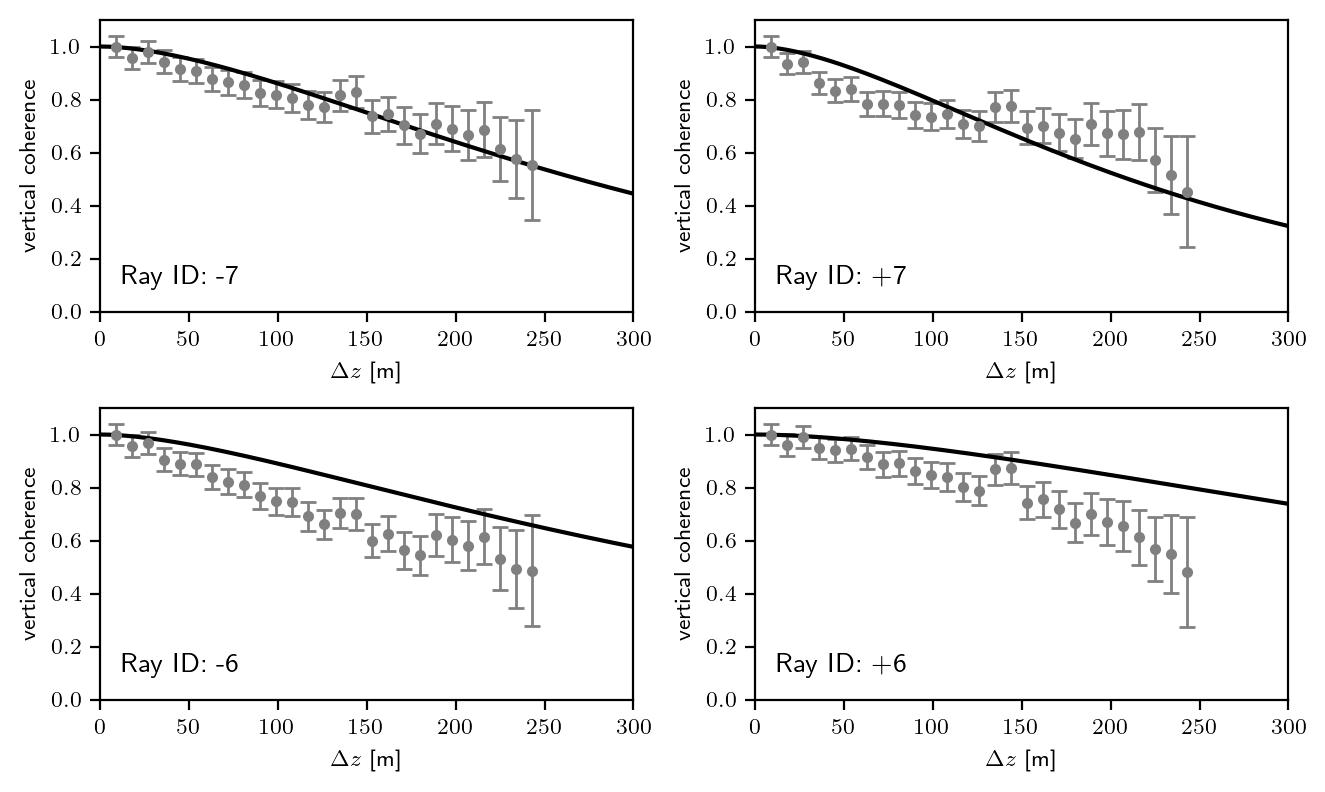

In [20]:
plt.rcParams["font.size"] = 8
plt.rcParams["text.usetex"] = True

fig, axes = plt.subplots(2, 2, figsize=(6.67, 4))
axes = axes.flatten()

ray_ids = ["-7", "+7", "-6", "+6"]

for k, ray_id in enumerate(ray_ids):
    plt.sca(axes[k])

    plt.errorbar(
        dz,
        MC[ray_id],
        np.sqrt(MC_var[ray_id]),
        elinewidth=1,
        lw=0,
        capsize=3,
        marker="o",
        markersize=3,
        color="gray",
    )

    plt.ylim([0, 1.1])

    plt.xlabel("$\\Delta z$ [m]")
    plt.ylabel("vertical coherence")

    plt.text(12, 0.1, f"Ray ID: {ray_id}", fontsize=10)

    plt.plot(delta_zr, np.exp(-Dzs[ray_id] / 2), c="k")

    plt.xlim([0, 300])
plt.tight_layout()

fig.savefig("../../figures/Ducted_VC.pdf", bbox_inches="tight")

## Make plot for bottom bounces

In [21]:
len(wavefront_values.keys())

25

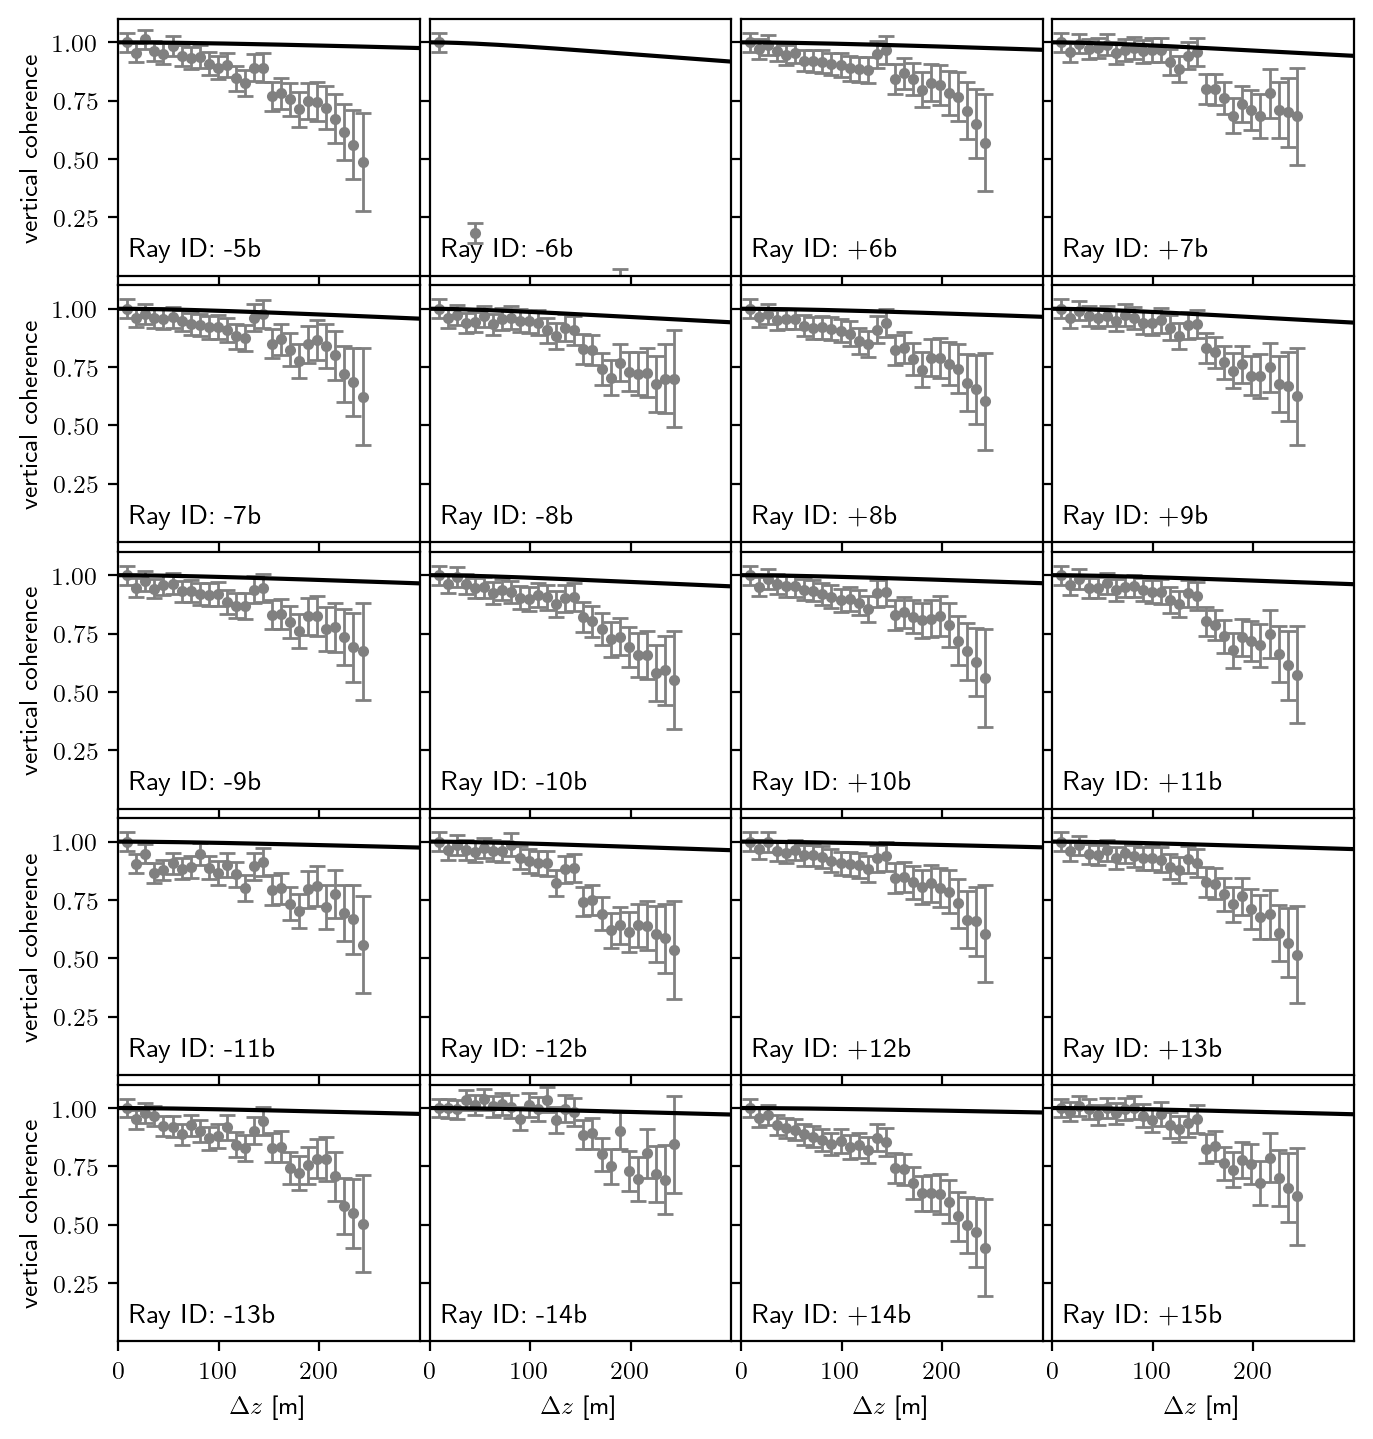

In [44]:
plt.rcParams["font.size"] = 9
plt.rcParams["text.usetex"] = True

fig, axes = plt.subplots(5, 4, figsize=(6.67, 7))
axes = axes.flatten()
ray_ids = list(wavefront_values.keys())

for k in range(0, 20):
    ray_id = ray_ids[k + 4]
    plt.sca(axes[k])

    plt.errorbar(
        dz,
        MC[ray_id],
        np.sqrt(MC_var[ray_id]),
        elinewidth=1,
        lw=0,
        capsize=3,
        marker="o",
        markersize=3,
        color="gray",
    )

    plt.ylim([0, 1.1])

    plt.ylabel("vertical coherence")

    plt.text(12, 0.08, f"Ray ID: {ray_id}", fontsize=10)

    plt.plot(delta_zr, np.exp(-Dzs[ray_id] / 2), c="k", zorder=10)

    plt.xlim([0, 300])

    if k < 16:
        plt.xlabel("")
        axes[k].set_xticklabels("")
    else:
        plt.xlabel("$\\Delta z$ [m]")
        plt.xticks(np.arange(0, 201, 100))

    if k % 4 == 0:
        plt.ylabel("vertical coherence")
        plt.yticks(np.arange(0.25, 1.1, 0.25))
    else:
        plt.ylabel("")
        axes[k].set_yticklabels("")


plt.tight_layout(pad=0)

fig.savefig("../../figures/Reflected_VC.pdf", bbox_inches="tight")